# LSTM-Based Sentiment Analysis of Movie Reviews
**Student Name:** Surya Prasad M  
**Register / Roll Number:** 24BAD119  


## Part A — Dataset Preparation
We use the IMDB movie-review dataset provided by Keras. It contains 25,000 training reviews and 25,000 test reviews, with binary labels: `0 = Negative` and `1 = Positive`. Reviews are represented as integer word IDs by Keras; we decode a few examples for inspection.

In [1]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
VOCAB_SIZE = 10000
MAX_LEN = 250
EMBEDDING_DIM = 64
LSTM_UNITS = 64
BATCH_SIZE = 128
EPOCHS = 5

(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Training reviews:", len(x_train_raw))
print("Testing reviews:", len(x_test_raw))
print("Training labels:", np.unique(y_train, return_counts=True))
print("Testing labels:", np.unique(y_test, return_counts=True))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
Training labels: (array([0, 1]), array([12500, 12500]))
Testing labels: (array([0, 1]), array([12500, 12500]))


In [3]:
word_index = imdb.get_word_index()
index_word = {index + 3: word for word, index in word_index.items()}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(index_word.get(int(token), "<UNK>") for token in sequence)

label_names = {0: "Negative", 1: "Positive"}
sample_rows = []
for i in range(5):
    sample_rows.append({
        "Review sample": decode_review(x_train_raw[i])[:500] + "...",
        "Label": int(y_train[i]),
        "Sentiment": label_names[int(y_train[i])]
    })

display(pd.DataFrame(sample_rows))
print("\nClass counts in training set:")
print(pd.Series(y_train).map(label_names).value_counts())

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Review sample,Label,Sentiment
0,<START> this film was just brilliant casting l...,1,Positive
1,<START> big hair big boobs bad music and a gia...,0,Negative
2,<START> this has to be one of the worst films ...,0,Negative
3,<START> the <UNK> <UNK> at storytelling the tr...,1,Positive
4,<START> worst mistake of my life br br i picke...,0,Negative



Class counts in training set:
Positive    12500
Negative    12500
Name: count, dtype: int64


In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

demo_text = "This Movie was AMAZING!!! I loved it. <br /> Great acting."
print("Before:", demo_text)
print("After: ", clean_text(demo_text))
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="post", truncating="post")
x_test = pad_sequences(x_test_raw, maxlen=MAX_LEN, padding="post", truncating="post")

print("Padded training shape:", x_train.shape)
print("Padded testing shape:", x_test.shape)
print("Example padded sequence:", x_train[0][:30])

Before: This Movie was AMAZING!!! I loved it. <br /> Great acting.
After:  this movie was amazing i loved it great acting
Padded training shape: (25000, 250)
Padded testing shape: (25000, 250)
Example padded sequence: [   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]


In [5]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

Training set: (20000, 250) (20000,)
Validation set: (5000, 250) (5000,)
Test set: (25000, 250) (25000,)


## Part B — Implementing the LSTM Model
The Embedding layer learns dense vectors for word IDs. The LSTM layer learns sequential context, and the sigmoid output produces a probability for the positive class.

In [6]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True, name="word_embedding"),
    LSTM(LSTM_UNITS, name="lstm"),
    Dropout(0.3, name="dropout"),
    Dense(1, activation="sigmoid", name="sentiment_output")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word_embedding (Embedding)      │ (None, 250, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

## Part C — Training and Performance Evaluation
The model is trained on the training set and monitored on the validation set. The separate test set is held out for final evaluation.

In [7]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 89s 535ms/step - accuracy: 0.7590 - loss: 0.4973 - val_accuracy: 0.8134 - val_loss: 0.4170
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 537ms/step - accuracy: 0.8832 - loss: 0.3035 - val_accuracy: 0.8460 - val_loss: 0.3657
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 525ms/step - accuracy: 0.9106 - loss: 0.2422 - val_accuracy: 0.8432 - val_loss: 0.3705
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 142s 524ms/step - accuracy: 0.9245 - loss: 0.2079 - val_accuracy: 0.8534 - val_loss: 0.3824
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 147s 555ms/step - accuracy: 0.9381 - loss: 0.1739 - val_accuracy: 0.8210 - val_loss: 0.4554


In [8]:
history_df = pd.DataFrame(history.history)
display(history_df)

last = history_df.iloc[-1]
print(f"Training accuracy:   {last['accuracy']:.4f}")
print(f"Validation accuracy: {last['val_accuracy']:.4f}")
print(f"Training loss:       {last['loss']:.4f}")
print(f"Validation loss:     {last['val_loss']:.4f}")

,accuracy,loss,val_accuracy,val_loss
0,0.75900,0.497298,0.8134,0.417030
1,0.88325,0.303517,0.8460,0.365742
2,0.91060,0.242219,0.8432,0.370506
3,0.92455,0.207857,0.8534,0.382399
4,0.93815,0.173930,0.8210,0.455449


Training accuracy:   0.9381
Validation accuracy: 0.8210
Training loss:       0.1739
Validation loss:     0.4554


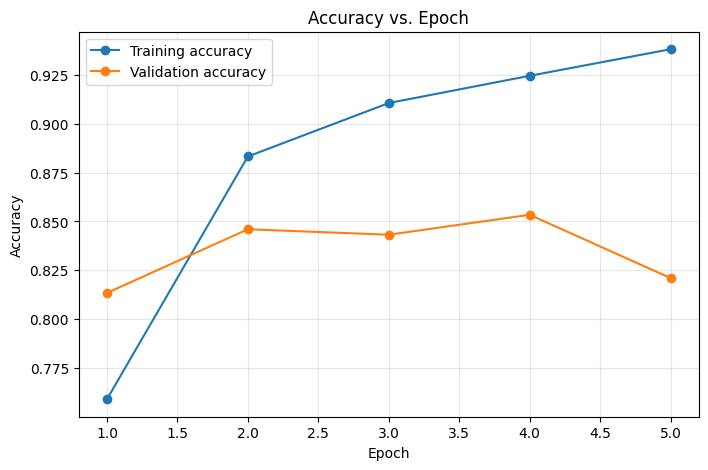

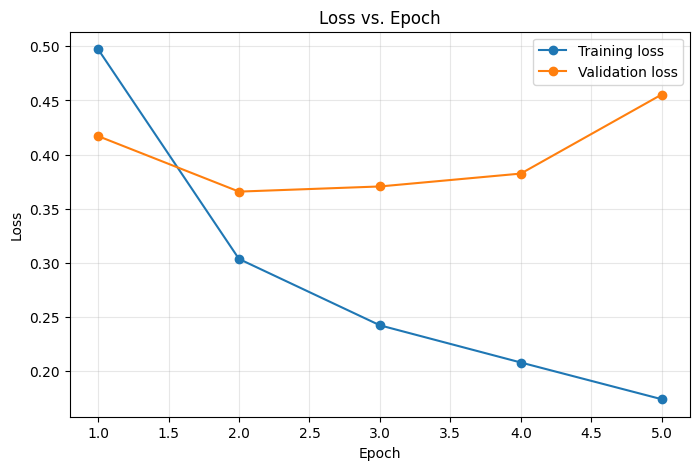

In [9]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Test loss", "Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [test_loss, accuracy, precision, recall, f1]
})
display(metrics_df)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))

,Metric,Score
0,Test loss,0.434788
1,Accuracy,0.824720
2,Precision,0.788938
3,Recall,0.886640
4,F1-score,0.834940



Classification report:
              precision    recall  f1-score   support

    Negative       0.87      0.76      0.81     12500
    Positive       0.79      0.89      0.83     12500

    accuracy                           0.82     25000
   macro avg       0.83      0.82      0.82     25000
weighted avg       0.83      0.82      0.82     25000



,Predicted Negative,Predicted Positive
Actual Negative,9535,2965
Actual Positive,1417,11083


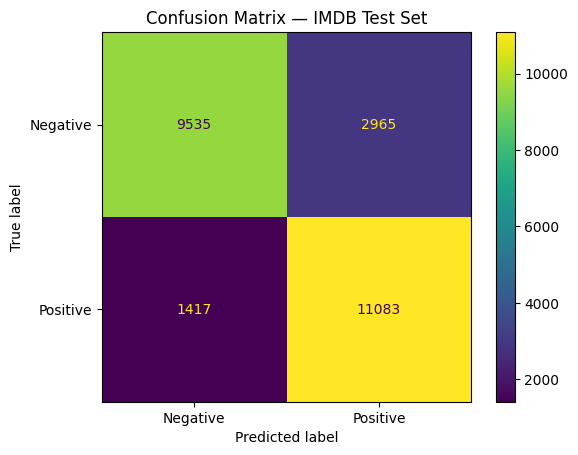

In [11]:
cm = confusion_matrix(y_test, y_pred)
display(pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(values_format="d")
plt.title("Confusion Matrix — IMDB Test Set")
plt.show()

## Part D — Sentiment Prediction and Experiment Management
The prediction function applies the same vocabulary and sequence length as training. Words not included in the selected vocabulary are mapped to the unknown-token ID. The examples below are illustrative; compare the model prediction with the expected sentiment.

In [12]:
pdef encode_raw_review(text):
    cleaned = clean_text(text)
    tokens = re.findall(r"[a-z0-9']+", cleaned)
    sequence = [1]  # <START>
    for token in tokens:
        original_id = word_index.get(token)
        if original_id is None:
            sequence.append(2)  # <UNK>
        else:
            keras_id = original_id + 3
            sequence.append(keras_id if keras_id < VOCAB_SIZE else 2)
    return pad_sequences([sequence], maxlen=MAX_LEN, padding="post", truncating="post")

def predict_sentiment(text):
    padded = encode_raw_review(text)
    probability = float(model.predict(padded, verbose=0)[0][0])
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    return sentiment, probability

reviews = [
    ("The acting was wonderful and the story kept me interested until the end.", "Positive"),
    ("A boring film with terrible dialogue and a completely disappointing ending.", "Negative"),
    ("I loved the performances, soundtrack, and emotional story.", "Positive"),
    ("The movie was slow, confusing, and not worth watching.", "Negative"),
    ("Some scenes were good, but overall I did not enjoy the film.", "Negative"),
    ("A charming and entertaining movie that I would happily watch again.", "Positive"),
]

results = []
for review, expected in reviews:
    predicted, probability = predict_sentiment(review)
    results.append({
        "Review": review,
        "Expected sentiment": expected,
        "Predicted sentiment": predicted,
        "Positive probability": round(probability, 4),
        "Correct?": predicted == expected
    })

predictions_df = pd.DataFrame(results)
display(predictions_df)

,Review,Expected sentiment,Predicted sentiment,Positive probability,Correct?
0,The acting was wonderful and the story kept me...,Positive,Positive,0.9605,True
1,A boring film with terrible dialogue and a com...,Negative,Negative,0.0145,True
2,"I loved the performances, soundtrack, and emot...",Positive,Positive,0.9610,True
3,"The movie was slow, confusing, and not worth w...",Negative,Negative,0.2648,True
4,"Some scenes were good, but overall I did not e...",Negative,Positive,0.8024,False
5,A charming and entertaining movie that I would...,Positive,Positive,0.9482,True
